# Análise de Dados

### Importando as Bibliotecas

In [1]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

### Importando a Base de Dados

In [2]:
df = pd.read_csv('https://github.com/futpythontrader/YouTube/raw/main/Bases_de_Dados/FlashScore/Base_de_Dados_FlashScore_v2.csv')
columns = ['Date','League','Home','Away','Season','Goals_H','Goals_A','Odd_H','Odd_D','Odd_A','Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No','Goals_Minutes_Home','Goals_Minutes_Away']
df = df[columns]
df = drop_reset_index(df)

### Análise Exploratória dos Dados

In [3]:
df.head()

,Date,League,Home,Away,Season,Goals_H,Goals_A,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No,Goals_Minutes_Home,Goals_Minutes_Away
1,2019-01-19,BOLIVIA - DIVISION PROFESIONAL,Sport Boys,Always Ready,2019,1,1,1.61,4.20,4.50,1.47,2.60,1.50,2.50,[45],[65]
2,2019-01-19,BOLIVIA - DIVISION PROFESIONAL,Real Potosi,Guabira,2019,3,1,1.57,3.80,5.00,1.53,2.40,1.57,2.25,"[20, 49, 82]",[37]
3,2019-01-19,BOLIVIA - DIVISION PROFESIONAL,The Strongest,Aurora,2019,2,1,1.18,6.50,10.00,1.30,3.50,1.72,2.00,"[15, 83]",[69]
4,2019-01-20,BOLIVIA - DIVISION PROFESIONAL,Destroyers,Blooming,2019,1,0,2.87,3.30,2.25,1.85,1.95,1.66,2.10,[45],[]
5,2019-01-20,BOLIVIA - DIVISION PROFESIONAL,San Jose,Nacional Potosi,2019,2,2,1.44,4.75,5.25,1.33,3.40,1.44,2.62,"[30, 88]","[37, 82]"


In [4]:
df.tail()

,Date,League,Home,Away,Season,Goals_H,Goals_A,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No,Goals_Minutes_Home,Goals_Minutes_Away
117438,2024-06-01,JAPAN - J1 LEAGUE,Machida,Albirex Niigata,2024,1,3,1.70,3.75,4.75,1.98,1.88,1.91,1.91,[27],"[24, 45, 52]"
117439,2024-06-01,JAPAN - J1 LEAGUE,Shonan Bellmare,Gamba Osaka,2024,1,2,2.88,3.10,2.50,2.15,1.67,1.91,1.91,[78],"[29, 65]"
117440,2024-06-01,JAPAN - J1 LEAGUE,Urawa Reds,Vissel Kobe,2024,1,1,3.00,3.25,2.40,1.98,1.88,1.70,2.05,[61],[16]
117441,2024-06-01,JAPAN - J1 LEAGUE,Kyoto,Cerezo Osaka,2024,1,1,3.70,3.40,2.05,2.08,1.73,1.95,1.80,[55],[33]
117442,2024-06-01,ESTONIA - MEISTRILIIGA,Flora,Paide,2024,2,0,2.50,3.45,2.40,1.53,2.18,1.59,2.28,"[15, 32]",[]


In [5]:
display(df)

,Date,League,Home,Away,Season,Goals_H,Goals_A,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No,Goals_Minutes_Home,Goals_Minutes_Away
1,2019-01-19,BOLIVIA - DIVISION PROFESIONAL,Sport Boys,Always Ready,2019,1,1,1.61,4.20,4.50,1.47,2.60,1.50,2.50,[45],[65]
2,2019-01-19,BOLIVIA - DIVISION PROFESIONAL,Real Potosi,Guabira,2019,3,1,1.57,3.80,5.00,1.53,2.40,1.57,2.25,"[20, 49, 82]",[37]
3,2019-01-19,BOLIVIA - DIVISION PROFESIONAL,The Strongest,Aurora,2019,2,1,1.18,6.50,10.00,1.30,3.50,1.72,2.00,"[15, 83]",[69]
4,2019-01-20,BOLIVIA - DIVISION PROFESIONAL,Destroyers,Blooming,2019,1,0,2.87,3.30,2.25,1.85,1.95,1.66,2.10,[45],[]
5,2019-01-20,BOLIVIA - DIVISION PROFESIONAL,San Jose,Nacional Potosi,2019,2,2,1.44,4.75,5.25,1.33,3.40,1.44,2.62,"[30, 88]","[37, 82]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117438,2024-06-01,JAPAN - J1 LEAGUE,Machida,Albirex Niigata,2024,1,3,1.70,3.75,4.75,1.98,1.88,1.91,1.91,[27],"[24, 45, 52]"
117439,2024-06-01,JAPAN - J1 LEAGUE,Shonan Bellmare,Gamba Osaka,2024,1,2,2.88,3.10,2.50,2.15,1.67,1.91,1.91,[78],"[29, 65]"
117440,2024-06-01,JAPAN - J1 LEAGUE,Urawa Reds,Vissel Kobe,2024,1,1,3.00,3.25,2.40,1.98,1.88,1.70,2.05,[61],[16]
117441,2024-06-01,JAPAN - J1 LEAGUE,Kyoto,Cerezo Osaka,2024,1,1,3.70,3.40,2.05,2.08,1.73,1.95,1.80,[55],[33]


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117442 entries, 1 to 117442
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Date                117442 non-null  object 
 1   League              117442 non-null  object 
 2   Home                117442 non-null  object 
 3   Away                117442 non-null  object 
 4   Season              117442 non-null  object 
 5   Goals_H             117442 non-null  int64  
 6   Goals_A             117442 non-null  int64  
 7   Odd_H               117442 non-null  float64
 8   Odd_D               117442 non-null  float64
 9   Odd_A               117442 non-null  float64
 10  Odd_Over25          117442 non-null  float64
 11  Odd_Under25         117442 non-null  float64
 12  Odd_BTTS_Yes        117442 non-null  float64
 13  Odd_BTTS_No         117442 non-null  float64
 14  Goals_Minutes_Home  117442 non-null  object 
 15  Goals_Minutes_Away  117442 non-nul

In [7]:
df.describe()

,Goals_H,Goals_A,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No
count,117442.000000,117442.000000,117442.000000,117442.000000,117442.000000,117442.000000,117442.000000,117442.000000,117442.000000
mean,1.457800,1.163008,2.552163,3.642216,3.923876,1.963844,1.886344,1.861619,1.867260
std,1.270029,1.132488,1.728902,1.100791,3.124875,0.421383,0.491935,0.350136,0.360805
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,1.750000,3.200000,2.400000,1.700000,1.610000,1.700000,1.700000
50%,1.000000,1.000000,2.200000,3.400000,3.200000,1.980000,1.800000,1.830000,1.830000
75%,2.000000,2.000000,2.850000,3.800000,4.500000,2.200000,2.080000,2.020000,2.020000
max,18.000000,12.000000,67.000000,26.000000,292.000000,4.330000,13.000000,11.000000,4.970000


### Operações Básicas com o Pandas (Criação de Variáveis)

### Probabilidades

In [8]:
df['p_H'] = 1 / df['Odd_H']
df['p_D'] = 1 / df['Odd_D']
df['p_A'] = 1 / df['Odd_A']
df['p_Over'] = 1 / df['Odd_Over25']
df['p_Under'] = 1 / df['Odd_Under25']
df['p_BTTS_Y'] = 1 / df['Odd_BTTS_Yes']
df['p_BTTS_N'] = 1 / df['Odd_BTTS_No']
# df['p_0x0'] = 1 / df['Odd_0x0']
# df['p_0x1'] = 1 / df['Odd_0x1']
# df['p_1x0'] = 1 / df['Odd_1x0']

### CV das Odds do Match Odds

In [9]:
desvio_padrao = df[['p_H','p_D','p_A']].std(axis=1)
media = df[['p_H','p_D','p_A']].mean(axis=1)
cv_odds = desvio_padrao / media
df['CV_Odds_MO'] = cv_odds

### Média de Pontos (PPG)

In [10]:
n_per = 5

df['Ptos_H'] = np.where(df['Goals_H'] > df['Goals_A'], 3, np.where(df['Goals_H'] == df['Goals_A'], 1, 0))
df['Ptos_A'] = np.where(df['Goals_A'] > df['Goals_H'], 3, np.where(df['Goals_A'] == df['Goals_H'], 1, 0))

df['Media_Ptos_H'] = df.groupby('Home')['Ptos_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_Ptos_A'] = df.groupby('Away')['Ptos_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_Ptos_H'] = df.groupby('Home')['Media_Ptos_H'].shift(1)
df['Media_Ptos_A'] = df.groupby('Away')['Media_Ptos_A'].shift(1)

df['DesvPad_Ptos_H'] = df.groupby('Home')['Ptos_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_Ptos_A'] = df.groupby('Away')['Ptos_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_Ptos_H'] = df.groupby('Home')['DesvPad_Ptos_H'].shift(1)
df['DesvPad_Ptos_A'] = df.groupby('Away')['DesvPad_Ptos_A'].shift(1)

df['CV_Ptos_H'] = df['DesvPad_Ptos_H'] / df['Media_Ptos_H']
df['CV_Ptos_A'] = df['DesvPad_Ptos_A'] / df['Media_Ptos_A']

### Média de Gols Marcados

In [11]:
df['Media_GM_H'] = df.groupby('Home')['Goals_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GM_A'] = df.groupby('Away')['Goals_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GM_H'] = df.groupby('Home')['Media_GM_H'].shift(1)
df['Media_GM_A'] = df.groupby('Away')['Media_GM_A'].shift(1)

df['DesvPad_GM_H'] = df.groupby('Home')['Goals_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GM_A'] = df.groupby('Away')['Goals_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GM_H'] = df.groupby('Home')['DesvPad_GM_H'].shift(1)
df['DesvPad_GM_A'] = df.groupby('Away')['DesvPad_GM_A'].shift(1)

df['CV_GM_H'] = df['DesvPad_GM_H'] / df['Media_GM_H']
df['CV_GM_A'] = df['DesvPad_GM_A'] / df['Media_GM_A']

### Média de Gols Sofridos

In [12]:
df['Media_GS_H'] = df.groupby('Home')['Goals_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GS_A'] = df.groupby('Away')['Goals_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GS_H'] = df.groupby('Home')['Media_GS_H'].shift(1)
df['Media_GS_A'] = df.groupby('Away')['Media_GS_A'].shift(1)

df['DesvPad_GS_H'] = df.groupby('Home')['Goals_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GS_A'] = df.groupby('Away')['Goals_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GS_H'] = df.groupby('Home')['DesvPad_GS_H'].shift(1)
df['DesvPad_GS_A'] = df.groupby('Away')['DesvPad_GS_A'].shift(1)

df['CV_GS_H'] = df['DesvPad_GS_H'] / df['Media_GS_H']
df['CV_GS_A'] = df['DesvPad_GS_A'] / df['Media_GS_A']

### Média de Saldo de Gols

In [13]:
df['SG_H'] = df['Goals_H'] - df['Goals_A']
df['SG_A'] = df['Goals_A'] - df['Goals_H']

df['Media_SG_H'] = df.groupby('Home')['SG_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A'] = df.groupby('Away')['SG_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H'] = df.groupby('Home')['Media_SG_H'].shift(1)
df['Media_SG_A'] = df.groupby('Away')['Media_SG_A'].shift(1)

df['DesvPad_SG_H'] = df.groupby('Home')['SG_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_A'] = df.groupby('Away')['SG_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_H'] = df.groupby('Home')['DesvPad_SG_H'].shift(1)
df['DesvPad_SG_A'] = df.groupby('Away')['DesvPad_SG_A'].shift(1)

df['CV_SG_H'] = df['DesvPad_SG_H'] / df['Media_SG_H']
df['CV_SG_A'] = df['DesvPad_SG_A'] / df['Media_SG_A']

### Média de Saldo de Gols Ponderado pela Probabilidade do Time

In [14]:
df['SG_H_01'] = (df['Goals_H'] - df['Goals_A']) / df['p_H']
df['SG_A_01'] = (df['Goals_A'] - df['Goals_H']) / df['p_A']

df['Media_SG_H_01'] = df.groupby('Home')['SG_H_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A_01'] = df.groupby('Away')['SG_A_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H_01'] = df.groupby('Home')['Media_SG_H_01'].shift(1)
df['Media_SG_A_01'] = df.groupby('Away')['Media_SG_A_01'].shift(1)

df['DesvPad_SG_H_01'] = df.groupby('Home')['SG_H_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_A_01'] = df.groupby('Away')['SG_A_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_H_01'] = df.groupby('Home')['DesvPad_SG_H_01'].shift(1)
df['DesvPad_SG_A_01'] = df.groupby('Away')['DesvPad_SG_A_01'].shift(1)

df['CV_SG_H_01'] = df['DesvPad_SG_H_01'] / df['Media_SG_H_01']
df['CV_SG_A_01'] = df['DesvPad_SG_A_01'] / df['Media_SG_A_01']

### Média de Saldo de Gols Ponderado pela Probabilidade do Adversário

In [15]:
df['SG_H_02'] = (df['Goals_H'] - df['Goals_A']) / df['p_A']
df['SG_A_02'] = (df['Goals_A'] - df['Goals_H']) / df['p_H']

df['Media_SG_H_02'] = df.groupby('Home')['SG_H_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A_02'] = df.groupby('Away')['SG_A_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H_02'] = df.groupby('Home')['Media_SG_H_02'].shift(1)
df['Media_SG_A_02'] = df.groupby('Away')['Media_SG_A_02'].shift(1)

df['DesvPad_SG_H_02'] = df.groupby('Home')['SG_H_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_A_02'] = df.groupby('Away')['SG_A_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_H_02'] = df.groupby('Home')['DesvPad_SG_H_02'].shift(1)
df['DesvPad_SG_A_02'] = df.groupby('Away')['DesvPad_SG_A_02'].shift(1)

df['CV_SG_H_02'] = df['DesvPad_SG_H_02'] / df['Media_SG_H_02']
df['CV_SG_A_02'] = df['DesvPad_SG_A_02'] / df['Media_SG_A_02']

### Média do Valor do Gol

In [16]:
df['VG_H'] = df['Goals_H'] * df['p_A']
df['VG_A'] = df['Goals_A'] * df['p_H']

df['Media_VG_H'] = df.groupby('Home')['VG_H'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_VG_A'] = df.groupby('Away')['VG_A'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_VG_H'] = df.groupby('Home')['Media_VG_H'].shift(1)
df['Media_VG_A'] = df.groupby('Away')['Media_VG_A'].shift(1)

df['DesvPad_VG_H'] = df.groupby('Home')['VG_H'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_VG_A'] = df.groupby('Away')['VG_A'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_VG_H'] = df.groupby('Home')['DesvPad_VG_H'].shift(1)
df['DesvPad_VG_A'] = df.groupby('Away')['DesvPad_VG_A'].shift(1)

df['CV_VG_H'] = df['DesvPad_VG_H'] / df['Media_VG_H']
df['CV_VG_A'] = df['DesvPad_VG_A'] / df['Media_VG_A']

### Média do Custo do Gol

In [17]:
##### Versão Original #####

df['CG_H_00'] = df['p_H'] / df['Goals_H']
df['CG_A_00'] = df['p_A'] / df['Goals_A']

df.replace(np.inf, 1, inplace=True)

df['Media_CG_H_00'] = df.groupby('Home')['CG_H_00'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_00'] = df.groupby('Away')['CG_A_00'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_00'] = df.groupby('Home')['Media_CG_H_00'].shift(1)
df['Media_CG_A_00'] = df.groupby('Away')['Media_CG_A_00'].shift(1)

df['DesvPad_CG_H_00'] = df.groupby('Home')['CG_H_00'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_A_00'] = df.groupby('Away')['CG_A_00'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_H_00'] = df.groupby('Home')['DesvPad_CG_H_00'].shift(1)
df['DesvPad_CG_A_00'] = df.groupby('Away')['DesvPad_CG_A_00'].shift(1)

df['CV_CG_H_00'] = df['DesvPad_CG_H_00'] / df['Media_CG_H_00']
df['CV_CG_A_00'] = df['DesvPad_CG_A_00'] / df['Media_CG_A_00']

##### Versão 1.0 #####

df['CG_H_01'] = df['Goals_H'] / df['p_H']
df['CG_A_01'] = df['Goals_A'] / df['p_A']

df['Media_CG_H_01'] = df.groupby('Home')['CG_H_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_01'] = df.groupby('Away')['CG_A_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_01'] = df.groupby('Home')['Media_CG_H_01'].shift(1)
df['Media_CG_A_01'] = df.groupby('Away')['Media_CG_A_01'].shift(1)

df['DesvPad_CG_H_01'] = df.groupby('Home')['CG_H_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_A_01'] = df.groupby('Away')['CG_A_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_H_01'] = df.groupby('Home')['DesvPad_CG_H_01'].shift(1)
df['DesvPad_CG_A_01'] = df.groupby('Away')['DesvPad_CG_A_01'].shift(1)

df['CV_CG_H_01'] = df['DesvPad_CG_H_01'] / df['Media_CG_H_01']
df['CV_CG_A_01'] = df['DesvPad_CG_A_01'] / df['Media_CG_A_01']

##### Versão 2.0 #####

df['CG_H_02'] = ((df['Goals_H']/2) + (df['p_H']/2))
df['CG_A_02'] = ((df['Goals_A']/2) + (df['p_A']/2))

df['Media_CG_H_02'] = df.groupby('Home')['CG_H_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_02'] = df.groupby('Away')['CG_A_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_02'] = df.groupby('Home')['Media_CG_H_02'].shift(1)
df['Media_CG_A_02'] = df.groupby('Away')['Media_CG_A_02'].shift(1)

df['DesvPad_CG_H_02'] = df.groupby('Home')['CG_H_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_A_02'] = df.groupby('Away')['CG_A_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_H_02'] = df.groupby('Home')['DesvPad_CG_H_02'].shift(1)
df['DesvPad_CG_A_02'] = df.groupby('Away')['DesvPad_CG_A_02'].shift(1)

df['CV_CG_H_02'] = df['DesvPad_CG_H_02'] / df['Media_CG_H_02']
df['CV_CG_A_02'] = df['DesvPad_CG_A_02'] / df['Media_CG_A_02']

### Variáveis a partir das Odds

In [18]:
##### Razões entre as Probabilidades #####

df['VAR01'] = df['p_H'] / df['p_D']
df['VAR02'] = df['p_H'] / df['p_A']
df['VAR03'] = df['p_D'] / df['p_H']
df['VAR04'] = df['p_D'] / df['p_A']
df['VAR05'] = df['p_A'] / df['p_H']
df['VAR06'] = df['p_A'] / df['p_D']

df['VAR07'] = df['p_Over'] / df['p_Under']
df['VAR08'] = df['p_Under'] / df['p_Over']
df['VAR09'] = df['p_BTTS_Y'] / df['p_BTTS_N']
df['VAR10'] = df['p_BTTS_N'] / df['p_BTTS_Y']

df['VAR11'] = df['p_H'] / df['p_Over']
df['VAR12'] = df['p_D'] / df['p_Over']
df['VAR13'] = df['p_A'] / df['p_Over']

df['VAR14'] = df['p_H'] / df['p_Under']
df['VAR15'] = df['p_D'] / df['p_Under']
df['VAR16'] = df['p_A'] / df['p_Under']

df['VAR17'] = df['p_H'] / df['p_BTTS_Y']
df['VAR18'] = df['p_D'] / df['p_BTTS_Y']
df['VAR19'] = df['p_A'] / df['p_BTTS_Y']

df['VAR20'] = df['p_H'] / df['p_BTTS_N']
df['VAR21'] = df['p_D'] / df['p_BTTS_N']
df['VAR22'] = df['p_A'] / df['p_BTTS_N']

# df['VAR23'] = df['p_0x0'] / df['p_H']
# df['VAR24'] = df['p_0x0'] / df['p_D']
# df['VAR25'] = df['p_0x0'] / df['p_A']
# df['VAR26'] = df['p_0x0'] / df['p_Over']
# df['VAR27'] = df['p_0x0'] / df['p_Under']
# df['VAR28'] = df['p_0x0'] / df['p_BTTS_Y']
# df['VAR29'] = df['p_0x0'] / df['p_BTTS_N']

# df['VAR30'] = df['p_0x1'] / df['p_H']
# df['VAR31'] = df['p_0x1'] / df['p_D']
# df['VAR32'] = df['p_0x1'] / df['p_A']
# df['VAR33'] = df['p_0x1'] / df['p_Over']
# df['VAR34'] = df['p_0x1'] / df['p_Under']
# df['VAR35'] = df['p_0x1'] / df['p_BTTS_Y']
# df['VAR36'] = df['p_0x1'] / df['p_BTTS_N']

# df['VAR37'] = df['p_1x0'] / df['p_H']
# df['VAR38'] = df['p_1x0'] / df['p_D']
# df['VAR39'] = df['p_1x0'] / df['p_A']
# df['VAR40'] = df['p_1x0'] / df['p_Over']
# df['VAR41'] = df['p_1x0'] / df['p_Under']
# df['VAR42'] = df['p_1x0'] / df['p_BTTS_Y']
# df['VAR43'] = df['p_1x0'] / df['p_BTTS_N']

# df['VAR44'] = df['p_0x0'] / df['p_0x1']
# df['VAR45'] = df['p_0x0'] / df['p_1x0']
# df['VAR46'] = df['p_0x1'] / df['p_0x0']
# df['VAR47'] = df['p_0x1'] / df['p_1x0']
# df['VAR48'] = df['p_1x0'] / df['p_0x0']
# df['VAR49'] = df['p_1x0'] / df['p_0x1']

##### Coeficientes de Variações das Odds #####

df['VAR50'] = df[['Odd_H','Odd_D','Odd_A']].std(ddof=0, axis=1) / df[['Odd_H','Odd_D','Odd_A']].mean(axis=1)
df['VAR51'] = df[['Odd_Over25', 'Odd_Under25']].std(ddof=0, axis=1) / df[['Odd_Over25', 'Odd_Under25']].mean(axis=1)
df['VAR52'] = df[['Odd_BTTS_Yes', 'Odd_BTTS_No']].std(ddof=0, axis=1) / df[['Odd_BTTS_Yes', 'Odd_BTTS_No']].mean(axis=1)
# df['VAR53'] = df[['Odd_0x0', 'Odd_0x1', 'Odd_1x0']].std(ddof=0, axis=1) / df[['Odd_0x0', 'Odd_0x1', 'Odd_1x0']].mean(axis=1)

##### Distância Absoluta entre as Probabilidades #####

df['VAR54'] = np.abs(df['p_H'] - df['p_A'])
df['VAR55'] = np.abs(df['p_H'] - df['p_D'])
df['VAR56'] = np.abs(df['p_D'] - df['p_A'])
df['VAR57'] = np.abs(df['p_Over'] - df['p_Under'])
df['VAR58'] = np.abs(df['p_BTTS_Y'] - df['p_BTTS_N'])
# df['VAR59'] = np.abs(df['p_0x0'] - df['p_0x1'])
# df['VAR60'] = np.abs(df['p_0x0'] - df['p_1x0'])
# df['VAR61'] = np.abs(df['p_0x1'] - df['p_1x0'])

##### Distância Angular entre as Probabilidades #####

df['VAR62'] = np.degrees(np.arctan((df['p_A'] - df['p_H']) / 2))
df['VAR63'] = np.degrees(np.arctan((df['p_D'] - df['p_H']) / 2))
df['VAR64'] = np.degrees(np.arctan((df['p_A'] - df['p_D']) / 2))
df['VAR65'] = np.degrees(np.arctan((df['p_Under'] - df['p_Over']) / 2))
df['VAR66'] = np.degrees(np.arctan((df['p_BTTS_N'] - df['p_BTTS_Y']) / 2))
# df['VAR67'] = np.degrees(np.arctan((df['p_0x1'] - df['p_0x0']) / 2))
# df['VAR68'] = np.degrees(np.arctan((df['p_1x0'] - df['p_0x0']) / 2))
# df['VAR69'] = np.degrees(np.arctan((df['p_1x0'] - df['p_0x1']) / 2))

##### Distância Relativa entre as Probabilidades #####

df['VAR70'] = np.abs((df['p_H'] - df['p_A'])) / df['p_A']
df['VAR71'] = np.abs((df['p_H'] - df['p_D'])) / df['p_D']
df['VAR72'] = np.abs((df['p_D'] - df['p_A'])) / df['p_A']
df['VAR73'] = np.abs((df['p_Over'] - df['p_Under'])) / df['p_Under']
df['VAR74'] = np.abs((df['p_BTTS_Y'] - df['p_BTTS_N'])) / df['p_BTTS_N']
# df['VAR75'] = np.abs((df['p_0x0'] - df['p_0x1'])) / df['p_0x1']
# df['VAR76'] = np.abs((df['p_0x0'] - df['p_1x0'])) / df['p_1x0']
# df['VAR77'] = np.abs((df['p_0x1'] - df['p_1x0'])) / df['p_1x0']


In [19]:
colunas_deletar = ['Ptos_H','Ptos_A','SG_H','SG_A','SG_H_01','SG_A_01','SG_H_02','SG_A_02',
                   'VG_H','VG_A','CG_H_00','CG_A_00','CG_H_01','CG_A_01','CG_H_02','CG_A_02']

df = df.drop(colunas_deletar, axis=1)
df.replace(np.inf, np.nan, inplace=True)
df = drop_reset_index(df)

### Criando Variáveis de Alvo

In [28]:
df['Over05FT'] = ((df['Goals_H'] + df['Goals_A']) > 0).astype(int)
df['Over15FT'] = ((df['Goals_H'] + df['Goals_A']) > 1).astype(int)
df['Over25FT'] = ((df['Goals_H'] + df['Goals_A']) > 2).astype(int)

df['Lay0x1'] = np.where((df['Goals_H'] == 0) & (df['Goals_A'] == 1), 0, 1)
df['Lay1x0'] = np.where((df['Goals_H'] == 1) & (df['Goals_A'] == 0), 0, 1)

df['Lay_Gol_H'] = np.where((df['Goals_H'] >= 4) & (df['Goals_H'] > df['Goals_A']), 0, 1)
df['Lay_Gol_A'] = np.where((df['Goals_A'] >= 4) & (df['Goals_A'] > df['Goals_H']), 0, 1)

df['Back_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 1, 0)
df['Back_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 1, 0)
df['Back_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 1, 0)

df['Lay_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 0, 1)
df['Lay_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 0, 1)
df['Lay_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 0, 1)

# df.to_excel("Base_Flashscore_Variáveis.xlsx", index=False)

### Correlações

In [32]:
df0 = df[['Goals_H','Goals_A','p_H','p_D','p_A',
        #   'VAR54','VAR55','VAR56','VAR57','VAR58',
        #   'VAR62','VAR63','VAR64','VAR65','VAR66',
          'Lay_Away']]
df0

,Goals_H,Goals_A,p_H,p_D,p_A,Lay_Away
1,2,2,0.230947,0.238095,0.621118,1
2,0,1,0.344828,0.285714,0.434783,0
3,0,1,0.465116,0.303030,0.312500,0
4,1,3,0.303030,0.294118,0.500000,0
5,4,1,0.666667,0.263158,0.166667,1
...,...,...,...,...,...,...
91166,3,2,0.512821,0.285714,0.270270,1
91167,1,3,0.588235,0.266667,0.210526,0
91168,1,2,0.347222,0.322581,0.400000,0
91169,1,1,0.333333,0.307692,0.416667,1


In [33]:
correlacao = df0.corr()
correlacao

,Goals_H,Goals_A,p_H,p_D,p_A,Lay_Away
Goals_H,1.000000,-0.038196,0.330383,-0.234871,-0.289328,0.458023
Goals_A,-0.038196,1.000000,-0.272923,-0.039186,0.308976,-0.623313
p_H,0.330383,-0.272923,1.000000,-0.424261,-0.955955,0.313487
p_D,-0.234871,-0.039186,-0.424261,1.000000,0.168527,-0.044688
p_A,-0.289328,0.308976,-0.955955,0.168527,1.000000,-0.329049
Lay_Away,0.458023,-0.623313,0.313487,-0.044688,-0.329049,1.000000


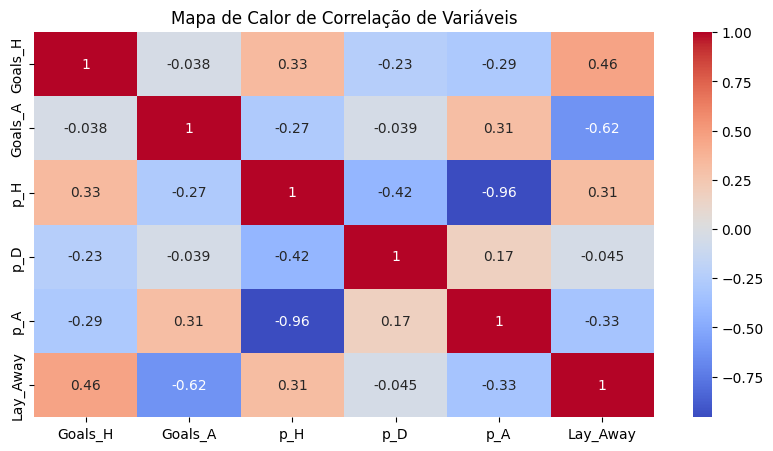

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize= (10,5))
sns.heatmap(correlacao, annot=True, cmap='coolwarm')
plt.title("Mapa de Calor de Correlação de Variáveis")
plt.show()


In [58]:
features = ['p_H','p_D','p_A','p_Over','p_Under','p_BTTS_Y','p_BTTS_N','CV_Odds_MO',
'Media_Ptos_H','Media_Ptos_A','DesvPad_Ptos_H','DesvPad_Ptos_A','CV_Ptos_H','CV_Ptos_A',
'Media_GM_H','Media_GM_A','DesvPad_GM_H','DesvPad_GM_A','CV_GM_H','CV_GM_A',
'Media_GS_H','Media_GS_A','DesvPad_GS_H','DesvPad_GS_A','CV_GS_H','CV_GS_A',
'Media_SG_H','Media_SG_A','DesvPad_SG_H','DesvPad_SG_A','CV_SG_H','CV_SG_A',
'Media_SG_H_01','Media_SG_A_01','DesvPad_SG_H_01','DesvPad_SG_A_01','CV_SG_H_01','CV_SG_A_01',
'Media_SG_H_02','Media_SG_A_02','DesvPad_SG_H_02','DesvPad_SG_A_02','CV_SG_H_02','CV_SG_A_02',
'Media_VG_H','Media_VG_A','DesvPad_VG_H','DesvPad_VG_A','CV_VG_H','CV_VG_A',
'Media_CG_H_00','Media_CG_A_00','DesvPad_CG_H_00','DesvPad_CG_A_00','CV_CG_H_00','CV_CG_A_00',
'Media_CG_H_01','Media_CG_A_01','DesvPad_CG_H_01','DesvPad_CG_A_01','CV_CG_H_01','CV_CG_A_01',
'Media_CG_H_02','Media_CG_A_02','DesvPad_CG_H_02','DesvPad_CG_A_02','CV_CG_H_02','CV_CG_A_02',
'VAR01',
'VAR02',
'VAR03',
'VAR04',
'VAR05',
'VAR06',
'VAR07',
'VAR08',
'VAR09',
'VAR10',
'VAR11',
'VAR12',
'VAR13',
'VAR14',
'VAR15',
'VAR16',
'VAR17',
'VAR18',
'VAR19',
'VAR20',
'VAR21',
'VAR22',
'VAR50',
'VAR51',
'VAR52',
'VAR54',
'VAR55',
'VAR56',
'VAR57',
'VAR58',
'VAR62',
'VAR63',
'VAR64',
'VAR65',
'VAR66',
'VAR70',
'VAR71',
'VAR72',
'VAR73',
'VAR74',
'Lay0x1']

In [59]:
df0 = df[features]
df0

,p_H,p_D,p_A,p_Over,p_Under,p_BTTS_Y,p_BTTS_N,CV_Odds_MO,Media_Ptos_H,Media_Ptos_A,DesvPad_Ptos_H,DesvPad_Ptos_A,CV_Ptos_H,CV_Ptos_A,Media_GM_H,Media_GM_A,DesvPad_GM_H,DesvPad_GM_A,CV_GM_H,CV_GM_A,Media_GS_H,Media_GS_A,DesvPad_GS_H,DesvPad_GS_A,CV_GS_H,CV_GS_A,Media_SG_H,Media_SG_A,DesvPad_SG_H,DesvPad_SG_A,CV_SG_H,CV_SG_A,Media_SG_H_01,Media_SG_A_01,DesvPad_SG_H_01,DesvPad_SG_A_01,CV_SG_H_01,CV_SG_A_01,Media_SG_H_02,Media_SG_A_02,DesvPad_SG_H_02,DesvPad_SG_A_02,CV_SG_H_02,CV_SG_A_02,Media_VG_H,Media_VG_A,DesvPad_VG_H,DesvPad_VG_A,CV_VG_H,CV_VG_A,Media_CG_H_00,Media_CG_A_00,DesvPad_CG_H_00,DesvPad_CG_A_00,CV_CG_H_00,CV_CG_A_00,Media_CG_H_01,Media_CG_A_01,DesvPad_CG_H_01,DesvPad_CG_A_01,CV_CG_H_01,CV_CG_A_01,Media_CG_H_02,Media_CG_A_02,DesvPad_CG_H_02,DesvPad_CG_A_02,CV_CG_H_02,CV_CG_A_02,VAR01,VAR02,VAR03,VAR04,VAR05,VAR06,VAR07,VAR08,VAR09,VAR10,VAR11,VAR12,VAR13,VAR14,VAR15,VAR16,VAR17,VAR18,VAR19,VAR20,VAR21,VAR22,VAR50,VAR51,VAR52,VAR54,VAR55,VAR56,VAR57,VAR58,VAR62,VAR63,VAR64,VAR65,VAR66,VAR70,VAR71,VAR72,VAR73,VAR74,Lay0x1
1,0.230947,0.238095,0.621118,0.714286,0.348432,0.714286,0.363636,0.614306,2.0,1.6,1.414214,1.341641,0.707107,0.838525,2.0,2.2,1.000000,1.303840,0.500000,0.592655,1.6,1.8,0.894427,1.788854,0.559017,0.993808,0.4,0.4,1.516575,1.140175,3.791438,2.850439,-0.142,1.516,3.474227,3.583661,-24.466390,2.363892,3.490,0.816,4.839463,2.204800,1.386666,2.701961,0.437817,0.903232,0.146131,0.607903,0.333771,0.673031,0.338920,0.247007,0.149215,0.145657,0.440266,0.589687,3.424,6.014,1.129364,3.644885,0.329838,0.606067,1.290850,1.299099,0.494112,0.585960,0.382780,0.451051,0.969977,0.371824,1.030952,0.383333,2.689441,2.608696,2.050000,0.487805,1.964286,0.509091,0.323326,0.333333,0.869565,0.662818,0.683333,1.782609,0.323326,0.333333,0.869565,0.635104,0.654762,1.708075,0.370622,0.344262,0.325301,0.390171,0.007148,0.383023,0.365854,0.350649,11.038932,0.204784,10.841523,-10.366323,-9.944294,0.628176,0.030023,0.616667,1.050000,0.964286,1
2,0.344828,0.285714,0.434783,0.621118,0.444444,0.653595,0.421941,0.211384,2.2,0.8,1.095445,1.303840,0.497930,1.629801,2.0,1.0,1.224745,1.414214,0.612372,1.414214,1.2,1.8,1.095445,0.836660,0.912871,0.464811,0.8,-0.8,0.836660,1.923538,1.045825,-2.404423,1.646,-5.290,1.685368,8.564835,1.023917,-1.619061,2.500,-1.154,2.167948,3.224541,0.867179,-2.794230,0.592828,0.434783,0.331184,0.549961,0.558651,1.264911,0.335203,0.660026,0.163553,0.416974,0.487923,0.631754,3.866,2.820,1.961975,3.607991,0.507495,1.279429,1.258330,0.649298,0.554308,0.656805,0.440511,1.011563,1.206897,0.793103,0.828571,0.657143,1.260870,1.521739,1.397516,0.715556,1.549020,0.645570,0.555172,0.460000,0.700000,0.775862,0.642857,0.978261,0.527586,0.437143,0.665217,0.817241,0.677143,1.030435,0.168930,0.165803,0.215385,0.089955,0.059113,0.149068,0.176674,0.231654,2.575286,-1.692978,4.262611,-5.048221,-6.606953,0.206897,0.206897,0.342857,0.397516,0.549020,0
3,0.465116,0.303030,0.312500,0.621118,0.444444,0.666667,0.400000,0.252543,2.4,0.8,1.341641,1.303840,0.559017,1.629801,1.4,0.4,0.547723,0.894427,0.391230,2.236068,0.8,1.2,1.303840,1.095445,1.629801,0.912871,0.6,-0.8,1.516575,1.483240,2.527625,-1.854050,1.774,-5.560,4.330970,10.017704,2.441359,-1.801745,1.528,-1.276,2.959050,1.942747,1.936551,-1.522529,0.670741,0.248447,0.333741,0.496894,0.497570,2.000000,0.270015,0.818182,0.110148,0.363636,0.407935,0.444444,4.704,2.200,2.603894,4.400000,0.553549,2.000000,0.864052,0.310352,0.231564,0.392584,0.267998,1.264962,1.534884,1.488372,0.651515,0.969697,0.671875,1.031250,1.397516,0.715556,1.666667,0.600000,0.748837,0.487879,0.503125,1.046512,0.681818,0.703125,0.697674,0.454545,0.468750,1.162791,0.757576,0.781250,0.180399,0.165803,0.250000,0.152616,0.162086,0.009470,0.176674,0.266667,-4.363678,-4.633295,0.271285,-5.048221,-7.594643,0.488372,0.534884,0.030303,0.397516,0.666667,0
4,0.303030,0.294118,0.500000,0.500000,0.555556,0.555556,0.526316,0.318222,0.6,1.4,0.547723,1.516575,0.912871,1.083268,0.6,1.4,0.547723,1.140175,0.912871,0.814411,1.0,1.2,0.

In [60]:
correlacao = df0.corr()

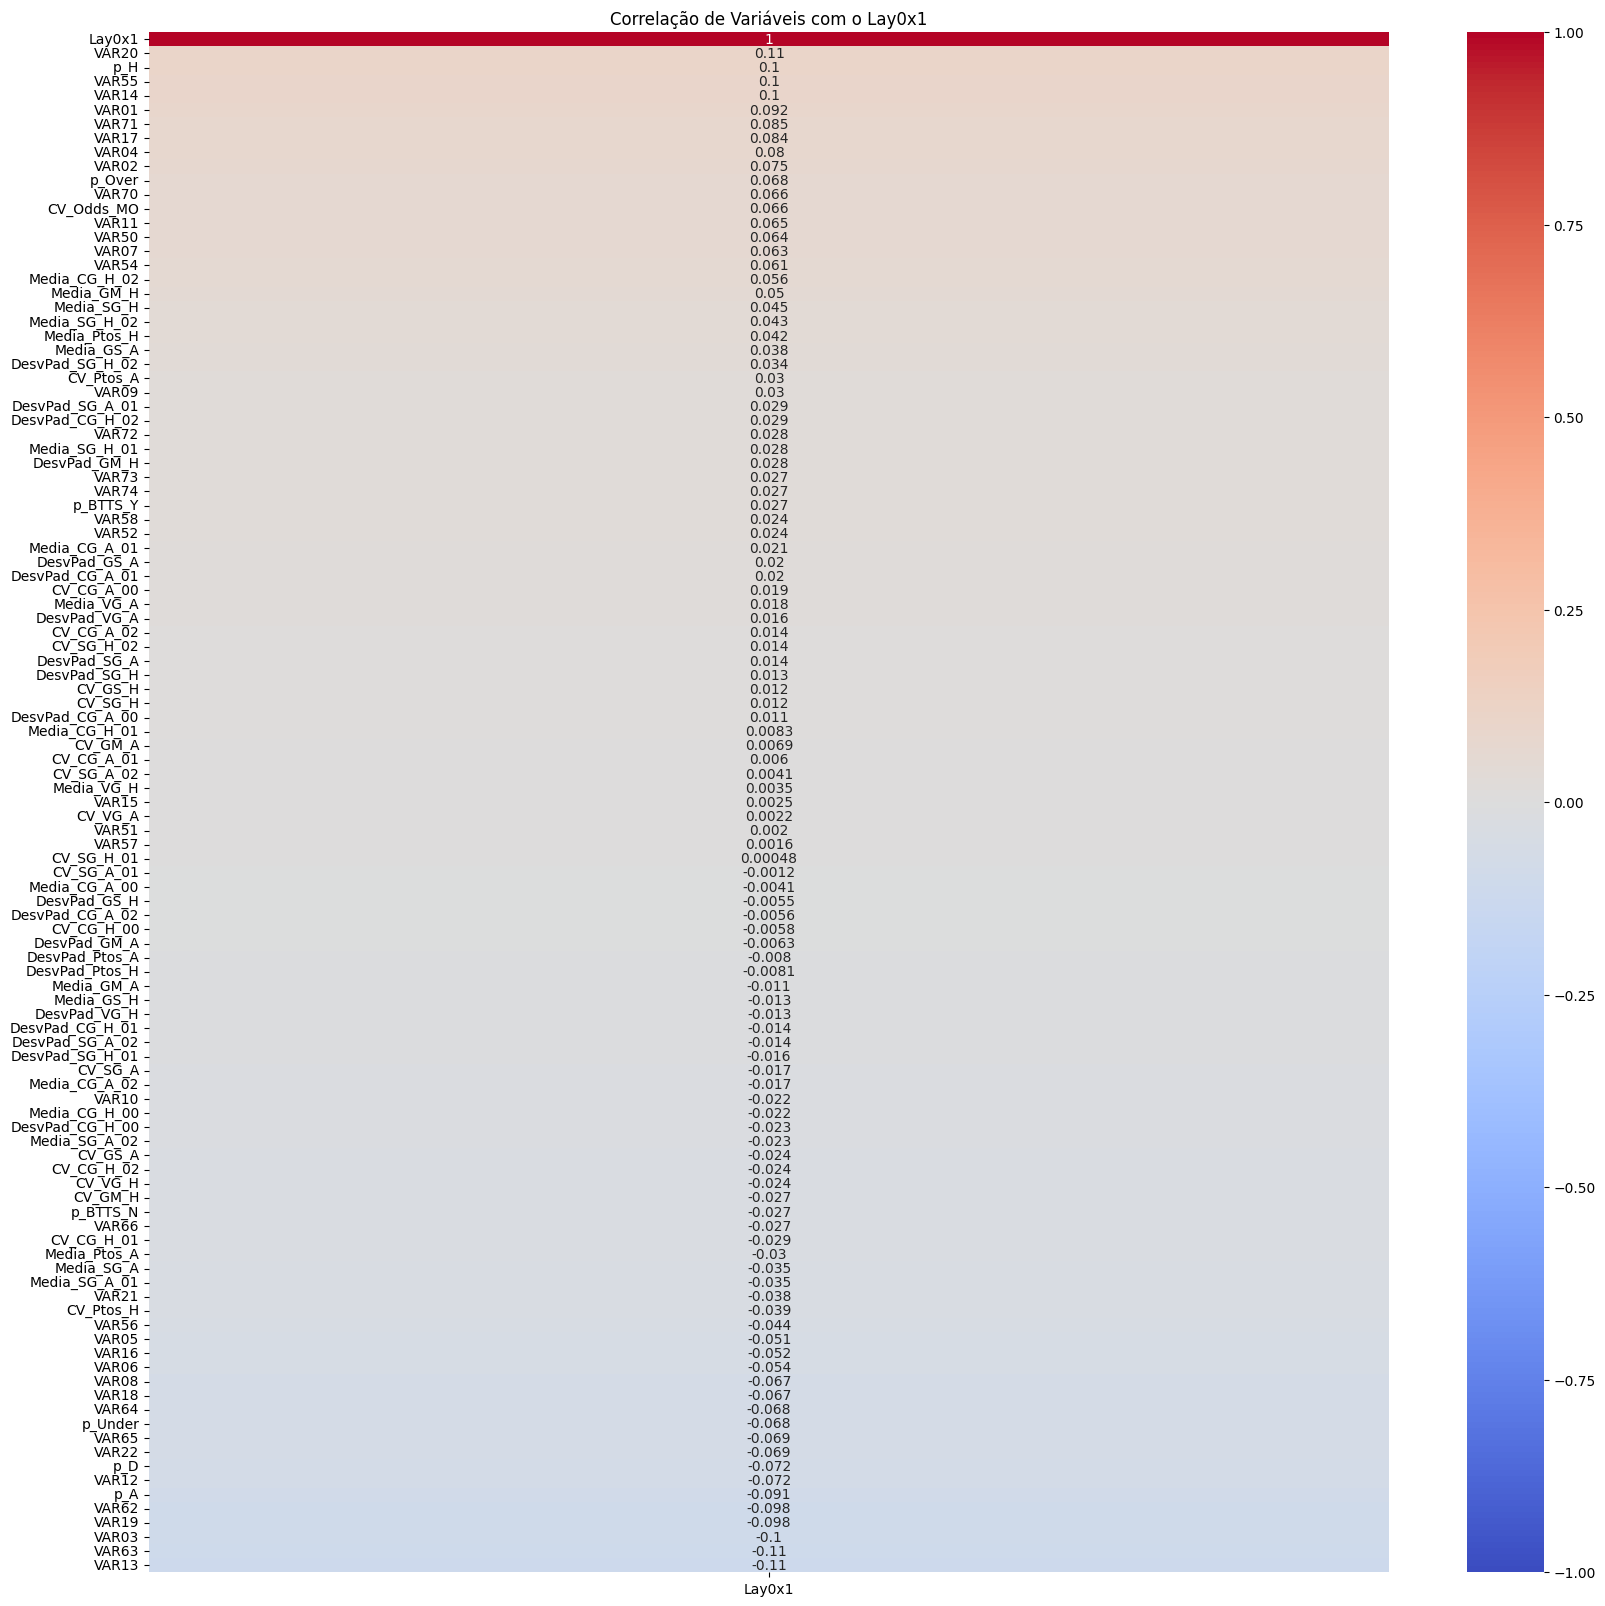

In [61]:
plt.figure(figsize= (20,20))

sns.heatmap(correlacao[['Lay0x1']].sort_values(by='Lay0x1', ascending=False),
            annot=True,
            cmap='coolwarm',
            vmin=-1,
            vmax=1)
plt.title("Correlação de Variáveis com o Lay0x1")
plt.show()